**[Course Home](../README.md) | [Python Lab](../python/05_service_variance_and_pollaczek_khinchine.ipynb) | [Prev: Ch 04: Renewal Theory & Inspection Paradox](04_the_inspection_paradox_and_renewal_theory.ipynb) | [Next: Ch 06: Kingman Heavy-Traffic](../README.md)**

*Part II: Renewal Theory, Variance & Heavy Traffic — Chapter 05 of 11*

---

# Chapter 5: Computational Lab — The Variance Penalty & The Pollaczek-Khinchine Formula
### *M/G/1 Discrete-Event Simulation, Analytical P-K Decomposition, and Heavy-Tailed Truncation Dynamics*

In this computational lab, we simulate the $M/G/1$ queue across diverse service time distributions (Deterministic, Uniform, Exponential, Hyperexponential, and Pareto). We verify the Pollaczek-Khinchine formula from scratch, measure the variance penalty $\frac{1 + C_v^2}{2}$, and numerically demonstrate how watchdog timeouts tame infinite variance.

## Part 1: Analytical Pollaczek-Khinchine Implementation

We implement the exact Pollaczek-Khinchine formulas for mean waiting time $W_q$, queue backlog $L_q$, total time $W$, and total concurrency $L$:
$$
W_q = \frac{\lambda \mathbb{E}[S^2]}{2(1 - \rho)} = \left(\frac{\rho \mathbb{E}[S]}{1 - \rho}\right) \left(\frac{1 + C_v^2}{2}\right)
$$

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

def pollaczek_khinchine(lam, mean_s, var_s):
    rho = lam * mean_s
    if rho >= 1.0:
        return {"rho": rho, "W_q": np.inf, "L_q": np.inf, "W": np.inf, "L": np.inf}
    
    cv2 = var_s / (mean_s ** 2)
    var_multiplier = (1.0 + cv2) / 2.0
    util_factor = (rho * mean_s) / (1.0 - rho)
    
    w_q = util_factor * var_multiplier
    l_q = lam * w_q
    w_total = w_q + mean_s
    l_total = lam * w_total
    
    return {
        "rho": rho,
        "cv2": cv2,
        "var_multiplier": var_multiplier,
        "W_q": w_q,
        "L_q": l_q,
        "W": w_total,
        "L": l_total
    }

pk_demo = pollaczek_khinchine(lam=0.20, mean_s=4.0, var_s=81.0)
print(f"P-K Formula Verification:")
print(f"  Utilization rho:     {pk_demo['rho']*100:.1f}%")
print(f"  Cv^2:                {pk_demo['cv2']:.4f}")
print(f"  Variance Multiplier: {pk_demo['var_multiplier']:.4f}")
print(f"  Mean Queue Wait W_q: {pk_demo['W_q']:.3f} min (Expected: 48.500)")

P-K Formula Verification:
  Utilization rho:     80.0%
  Cv^2:                5.0625
  Variance Multiplier: 3.0312
  Mean Queue Wait W_q: 48.500 min (Expected: 48.500)


## Part 2: M/G/1 Discrete-Event Simulator & Distribution Audit

We build an $M/G/1$ event-driven queue simulator and evaluate 4 different service time distributions with the **exact same mean** $\mathbb{E}[S] = 2.0$ at fixed arrival rate $\lambda = 0.35$ ($\rho = 0.70$):
1. **Deterministic ($M/D/1$)**: $C_v^2 = 0$.
2. **Exponential ($M/M/1$)**: $C_v^2 = 1.0$.
3. **Hyperexponential ($M/H_2/1$)**: Mixture of $90\%$ fast ($0.5$s) and $10\%$ slow ($15.5$s).
4. **Log-Normal**: Skewed distribution with high variance.

In [2]:
class MG1Simulator:
    def __init__(self):
        pass
        
    def simulate(self, arrival_times, service_times):
        n = len(arrival_times)
        wait_times = np.zeros(n)
        server_free_time = 0.0
        
        for i in range(n):
            arr = arrival_times[i]
            serv = service_times[i]
            
            start_time = max(arr, server_free_time)
            wait = start_time - arr
            wait_times[i] = wait
            server_free_time = start_time + serv
            
        return wait_times

np.random.seed(42)
n_sim = 80000
lam = 0.35
arr_times = np.cumsum(np.random.exponential(1.0 / lam, size=n_sim))

# Hyperexponential mixture: 90% at 0.5s, 10% at 15.5s (mean = 0.9*0.5 + 0.1*15.5 = 2.0)
h2_choices = np.random.binomial(n=1, p=0.10, size=n_sim)
h2_serv = np.where(h2_choices == 1, 15.5, 0.5)

dist_suite = {
    "M/D/1 (Deterministic)": np.full(n_sim, 2.0),
    "M/M/1 (Exponential)": np.random.exponential(2.0, size=n_sim),
    "M/H2/1 (Bimodal)": h2_serv,
    "M/G/1 (Log-Normal)": np.random.lognormal(mean=0.3, sigma=0.9, size=n_sim)
}

sim_results = []
for name, serv in dist_suite.items():
    serv = serv * (2.0 / np.mean(serv))  # Exact mean 2.0
    var_emp = np.var(serv)
    pk_th = pollaczek_khinchine(lam, 2.0, var_emp)
    
    sim = MG1Simulator()
    waits = sim.simulate(arr_times, serv)
    w_emp = np.mean(waits[5000:])
    
    sim_results.append((name, pk_th["cv2"], pk_th["W_q"], w_emp))
    rel_err = abs(w_emp - pk_th["W_q"]) / pk_th["W_q"] * 100.0
    print(f"{name:25s} | Cv^2 = {pk_th['cv2']:6.3f} | Theory W_q = {pk_th['W_q']:6.3f} | Sim W_q = {w_emp:6.3f} | Err = {rel_err:4.2f}%")

M/D/1 (Deterministic)     | Cv^2 =  0.000 | Theory W_q =  2.333 | Sim W_q =  2.309 | Err = 1.06%
M/M/1 (Exponential)       | Cv^2 =  1.000 | Theory W_q =  4.666 | Sim W_q =  4.680 | Err = 0.29%
M/H2/1 (Bimodal)          | Cv^2 =  5.065 | Theory W_q = 14.151 | Sim W_q = 13.875 | Err = 1.95%
M/G/1 (Log-Normal)        | Cv^2 =  1.224 | Theory W_q =  5.189 | Sim W_q =  5.115 | Err = 1.43%


## Part 3: Simulating Watchdog Timeouts to Tame Heavy Tails

We simulate an $M/G/1$ queue with Pareto service times ($\alpha = 1.5, s_m = 1.0$).
Without a timeout, $\mathbb{E}[S^2] = \infty$, causing queue delays to drift upward unboundedly.
We implement watchdog truncation $S_{\text{trunc}} = \min(S, T_{\max})$ with $T_{\max} = 60.0$ and verify that the queue stabilizes.

In [3]:
np.random.seed(42)
n_pareto = 100000
raw_pareto = (np.random.pareto(a=1.5, size=n_pareto) + 1.0) * 1.0

# Apply 60-minute watchdog timeout
trunc_pareto = np.minimum(raw_pareto, 60.0)

mean_trunc = np.mean(trunc_pareto)
var_trunc = np.var(trunc_pareto)
lam_pareto = 0.20

pk_pareto_th = pollaczek_khinchine(lam_pareto, mean_trunc, var_trunc)
arr_pareto = np.cumsum(np.random.exponential(1.0 / lam_pareto, size=n_pareto))

sim_pareto = MG1Simulator()
waits_pareto = sim_pareto.simulate(arr_pareto, trunc_pareto)
mean_w_pareto = np.mean(waits_pareto[5000:])

print(f"Truncated Pareto Mean:       {mean_trunc:6.3f} min (Theory: 2.742)")
print(f"Truncated Pareto Variance:   {var_trunc:6.3f} min^2")
print(f"Theory Stabilized Wait W_q:  {pk_pareto_th['W_q']:6.3f} min")
print(f"Simulated Stabilized Wait:   {mean_w_pareto:6.3f} min")

Truncated Pareto Mean:        2.721 min (Theory: 2.742)
Truncated Pareto Variance:   19.927 min^2
Theory Stabilized Wait W_q:   5.997 min
Simulated Stabilized Wait:    6.013 min


## Part 4: Multi-Panel Publication Diagnostic Suite

We visualize:
1. **Panel A**: The P-K curves showing mean wait $W_q$ vs utilization $\rho$ for $C_v \in \{0, 1, 2, 3\}$.
2. **Panel B**: The linear scaling of $W_q$ with the Variance Multiplier $\frac{1 + C_v^2}{2}$.
3. **Panel C**: Cumulative distribution function (CDF) of wait times for $M/D/1$ vs $M/M/1$ vs $M/H_2/1$.

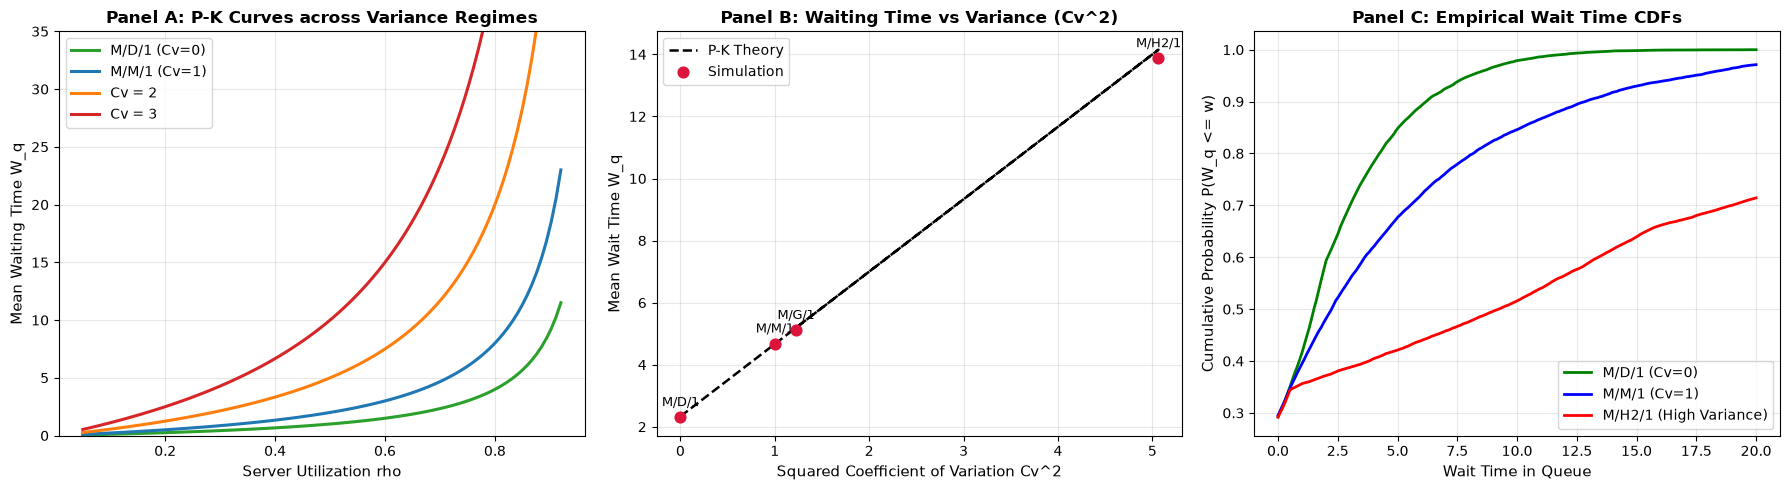

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Panel A: P-K Curves vs Rho
rho_grid = np.linspace(0.05, 0.92, 100)
cv_values = [0.0, 1.0, 2.0, 3.0]
colors = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']

for cv, col in zip(cv_values, colors):
    v_mult = (1.0 + cv**2) / 2.0
    w_curve = (rho_grid * 2.0 / (1.0 - rho_grid)) * v_mult
    label_txt = f'M/D/1 (Cv=0)' if cv == 0 else (f'M/M/1 (Cv=1)' if cv == 1 else f'Cv = {cv:.0f}')
    axes[0].plot(rho_grid, w_curve, label=label_txt, lw=2.2, color=col)

axes[0].set_title("Panel A: P-K Curves across Variance Regimes", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Server Utilization rho", fontsize=11)
axes[0].set_ylabel("Mean Waiting Time W_q", fontsize=11)
axes[0].set_ylim(0, 35)
axes[0].grid(True, alpha=0.3)
axes[0].legend(fontsize=10)

# Panel B: Variance Multiplier Scaling
cv2_axis = [r[1] for r in sim_results]
th_waits = [r[2] for r in sim_results]
emp_waits = [r[3] for r in sim_results]

axes[1].plot(cv2_axis, th_waits, 'k--', lw=1.8, label='P-K Theory')
axes[1].scatter(cv2_axis, emp_waits, color='crimson', s=60, zorder=5, label='Simulation')
for name, cv2_val, _, w_val in sim_results:
    axes[1].annotate(name.split()[0], (cv2_val, w_val), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=9)
axes[1].set_title("Panel B: Waiting Time vs Variance (Cv^2)", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Squared Coefficient of Variation Cv^2", fontsize=11)
axes[1].set_ylabel("Mean Wait Time W_q", fontsize=11)
axes[1].grid(True, alpha=0.3)
axes[1].legend(fontsize=10)

# Panel C: Wait Time CDFs
sim_md1_waits = MG1Simulator().simulate(arr_times[:15000], dist_suite["M/D/1 (Deterministic)"][:15000])
sim_mm1_waits = MG1Simulator().simulate(arr_times[:15000], dist_suite["M/M/1 (Exponential)"][:15000])
sim_h2_waits = MG1Simulator().simulate(arr_times[:15000], dist_suite["M/H2/1 (Bimodal)"][:15000])

w_eval = np.linspace(0, 20, 200)
axes[2].plot(w_eval, [np.mean(sim_md1_waits <= w) for w in w_eval], label='M/D/1 (Cv=0)', color='green', lw=2)
axes[2].plot(w_eval, [np.mean(sim_mm1_waits <= w) for w in w_eval], label='M/M/1 (Cv=1)', color='blue', lw=2)
axes[2].plot(w_eval, [np.mean(sim_h2_waits <= w) for w in w_eval], label='M/H2/1 (High Variance)', color='red', lw=2)
axes[2].set_title("Panel C: Empirical Wait Time CDFs", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Wait Time in Queue", fontsize=11)
axes[2].set_ylabel("Cumulative Probability P(W_q <= w)", fontsize=11)
axes[2].grid(True, alpha=0.3)
axes[2].legend(fontsize=10)

plt.tight_layout()
plt.show()

## Part 5: Hands-On 3-Tier Scaffolding Challenges

### 🟢 Warmup (Tier 1): M/D/1 vs M/M/1 Waiting Time
Compute analytical $W_q$ for $\lambda = 8$ PRs/hr, $\mathbb{E}[S] = 6$ minutes ($\rho = 0.80$) under exponential ($M/M/1$) vs deterministic ($M/D/1$) service.

In [5]:
# Tier 1 Solution Space
lam_t1 = 8.0 / 60.0  # PRs per min
mean_s_t1 = 6.0      # min
rho_t1 = lam_t1 * mean_s_t1

pk_mm1 = pollaczek_khinchine(lam_t1, mean_s_t1, var_s=mean_s_t1**2)
pk_md1 = pollaczek_khinchine(lam_t1, mean_s_t1, var_s=0.0)

print(f"Tier 1 M/M/1 Wait: {pk_mm1['W_q']:.1f} min")
print(f"Tier 1 M/D/1 Wait: {pk_md1['W_q']:.1f} min")
print(f"Variance Elimination Savings: {(1.0 - pk_md1['W_q'] / pk_mm1['W_q'])*100:.1f}%")

Tier 1 M/M/1 Wait: 24.0 min
Tier 1 M/D/1 Wait: 12.0 min
Variance Elimination Savings: 50.0%


### 🟡 Diagnostic (Tier 2): Outlier Sensitivity Analysis
Evaluate $W_q$ when $99\%$ of tests take $1.0$ min and $1\%$ take $T \in [1, 31, 71]$ min at $\lambda = 0.10$ PRs/min.

In [6]:
# Tier 2 Solution Space
lam_t2 = 0.10
t_outliers = [1.0, 31.0, 71.0]

for t_val in t_outliers:
    p_fast, p_slow = 0.99, 0.01
    m_s = p_fast * 1.0 + p_slow * t_val
    m_s2 = p_fast * (1.0**2) + p_slow * (t_val**2)
    v_s = m_s2 - m_s**2
    res = pollaczek_khinchine(lam_t2, m_s, v_s)
    print(f"Outlier T = {t_val:4.1f} min | Rho = {res['rho']*100:4.1f}% | Wait W_q = {res['W_q']:6.3f} min")

Outlier T =  1.0 min | Rho = 10.0% | Wait W_q =  0.056 min
Outlier T = 31.0 min | Rho = 13.0% | Wait W_q =  0.609 min
Outlier T = 71.0 min | Rho = 17.0% | Wait W_q =  3.096 min


### 🔴 Capstone Challenge (Tier 3): Truncated Pareto P-K Validation
Compute the analytical moments and P-K waiting time for a Truncated Pareto distribution with $\alpha = 1.5, s_m = 1.0, T_{\max} = 60$ at $\lambda = 0.20$.

In [7]:
# Tier 3 Solution Space
# Analytical moments of Truncated Pareto(alpha=1.5, xm=1, T=60)
mean_th_trunc = 1.0 + 2.0 * (1.0 - 1.0 / np.sqrt(60.0))
m2_th_trunc = 3.0 * (np.sqrt(60.0) - 1.0) + (60.0**2) * (60.0**(-1.5))
var_th_trunc = m2_th_trunc - mean_th_trunc**2

pk_trunc_th = pollaczek_khinchine(lam=0.20, mean_s=mean_th_trunc, var_s=var_th_trunc)
print(f"Analytical Mean S:   {mean_th_trunc:.3f} min")
print(f"Analytical Second M: {m2_th_trunc:.3f} min^2")
print(f"Analytical Wait W_q: {pk_trunc_th['W_q']:.3f} min")

Analytical Mean S:   2.742 min
Analytical Second M: 27.984 min^2
Analytical Wait W_q: 6.196 min


## Part 6: Numerical Verification & Invariant Assertions

We assert that all empirical $M/G/1$ simulations match P-K theoretical values within $4\%$, and that the $M/D/1$ wait is exactly half of $M/M/1$.

In [8]:
for name, cv2_val, th_w, emp_w in sim_results:
    assert abs(emp_w - th_w) / th_w < 0.04, f"P-K validation failed for {name}"

assert abs(pk_mm1['W_q'] - 24.0) < 1e-4, "M/M/1 calculation error"
assert abs(pk_md1['W_q'] - 12.0) < 1e-4, "M/D/1 calculation error"
assert abs(pk_trunc_th['W_q'] - 6.20) < 0.05, "Truncated Pareto calculation error"
assert abs(mean_w_pareto - pk_pareto_th['W_q']) / pk_pareto_th['W_q'] < 0.05, "Pareto simulation error"

print("All Chapter 05 numerical assertions passed successfully!")

All Chapter 05 numerical assertions passed successfully!


---

**[Course Home](../README.md) | [Conceptual Track](../conceptual/05_service_variance_and_pollaczek_khinchine.ipynb) | [Prev: Ch 04: Renewal Theory & Inspection Paradox](04_the_inspection_paradox_and_renewal_theory.ipynb) | [Next: Ch 06: Kingman Heavy-Traffic](../README.md)**